## ML Assignment 1 - Uber Fare Prediction
Predict the price of an Uber ride from a given pickup point to the agreed drop-off location.

1. Pre-process the dataset
2. Identify outliers
3. Check the correlation
4. Implement **Linear Regression** and **Random Forest Regression** from scratch
5. Evaluate & compare models (R², RMSE, MAE, MSE)


## Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style='darkgrid', palette='muted')
plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 13, 'axes.labelsize': 11})

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print('Libraries loaded successfully')

Libraries loaded successfully



## Pre-processing the Dataset

In [ ]:
df = pd.read_csv('uber.csv')
print(f'Shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head()

: 

In [4]:
print('=== Data Types ===')
print(df.dtypes)
print('\n=== Statistical Summary ===')
df.describe()

=== Data Types ===
Unnamed: 0             int64
key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

=== Statistical Summary ===


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [5]:
print('=== Missing Values ===')
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df)) * 100
null_df = pd.DataFrame({'Count': null_counts, 'Percentage (%)': null_pct.round(4)})
print(null_df[null_df['Count'] > 0])

=== Missing Values ===
                   Count  Percentage (%)
dropoff_longitude      1          0.0005
dropoff_latitude       1          0.0005


In [6]:
# Drop irrelevant columns
df.drop(columns=['Unnamed: 0', 'key'], inplace=True)

# Drop rows with missing values
df.dropna(inplace=True)
print(f'Shape after dropping nulls: {df.shape}')

Shape after dropping nulls: (199999, 7)


In [7]:
# Parse datetime and extract features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], errors='coerce')
df['hour']       = df['pickup_datetime'].dt.hour
df['day']        = df['pickup_datetime'].dt.day
df['month']      = df['pickup_datetime'].dt.month
df['year']       = df['pickup_datetime'].dt.year
df['dayofweek']  = df['pickup_datetime'].dt.dayofweek
df['is_weekend'] = df['dayofweek'].apply(lambda x: 1 if x >= 5 else 0)
df.drop(columns=['pickup_datetime'], inplace=True)
print('Datetime features extracted.')
df[['hour','day','month','year','dayofweek','is_weekend']].head(3)

Datetime features extracted.


,hour,day,month,year,dayofweek,is_weekend
0,19,7,5,2015,3,0
1,20,17,7,2009,4,0
2,21,24,8,2009,0,0


In [8]:
print(f'Before cleaning: {df.shape}')

# Filter invalid fares
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] <= 500)]

# Filter invalid passenger counts
df = df[(df['passenger_count'] >= 1) & (df['passenger_count'] <= 6)]

# Filter to NYC bounding box
lat_min, lat_max =  40.40,  41.80
lon_min, lon_max = -74.80, -72.60
df = df[
    (df['pickup_latitude'].between(lat_min, lat_max)) &
    (df['pickup_longitude'].between(lon_min, lon_max)) &
    (df['dropoff_latitude'].between(lat_min, lat_max)) &
    (df['dropoff_longitude'].between(lon_min, lon_max))
]
df.reset_index(drop=True, inplace=True)
print(f'After geographic/fare/passenger filter: {df.shape}')

Before cleaning: (199999, 12)
After geographic/fare/passenger filter: (195083, 12)


In [9]:
def haversine_distance(lat1, lon1, lat2, lon2):
    """Compute great-circle distance in km using Haversine formula."""
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return R * 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))

df['distance_km'] = haversine_distance(
    df['pickup_latitude'].values, df['pickup_longitude'].values,
    df['dropoff_latitude'].values, df['dropoff_longitude'].values
)
df = df[df['distance_km'] > 0].reset_index(drop=True)
print(f'Final dataset shape: {df.shape}')
df.head(3)

Final dataset shape: (193054, 13)


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,is_weekend,distance_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3,0,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4,0,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0,0,5.036377


## Outlier Detection

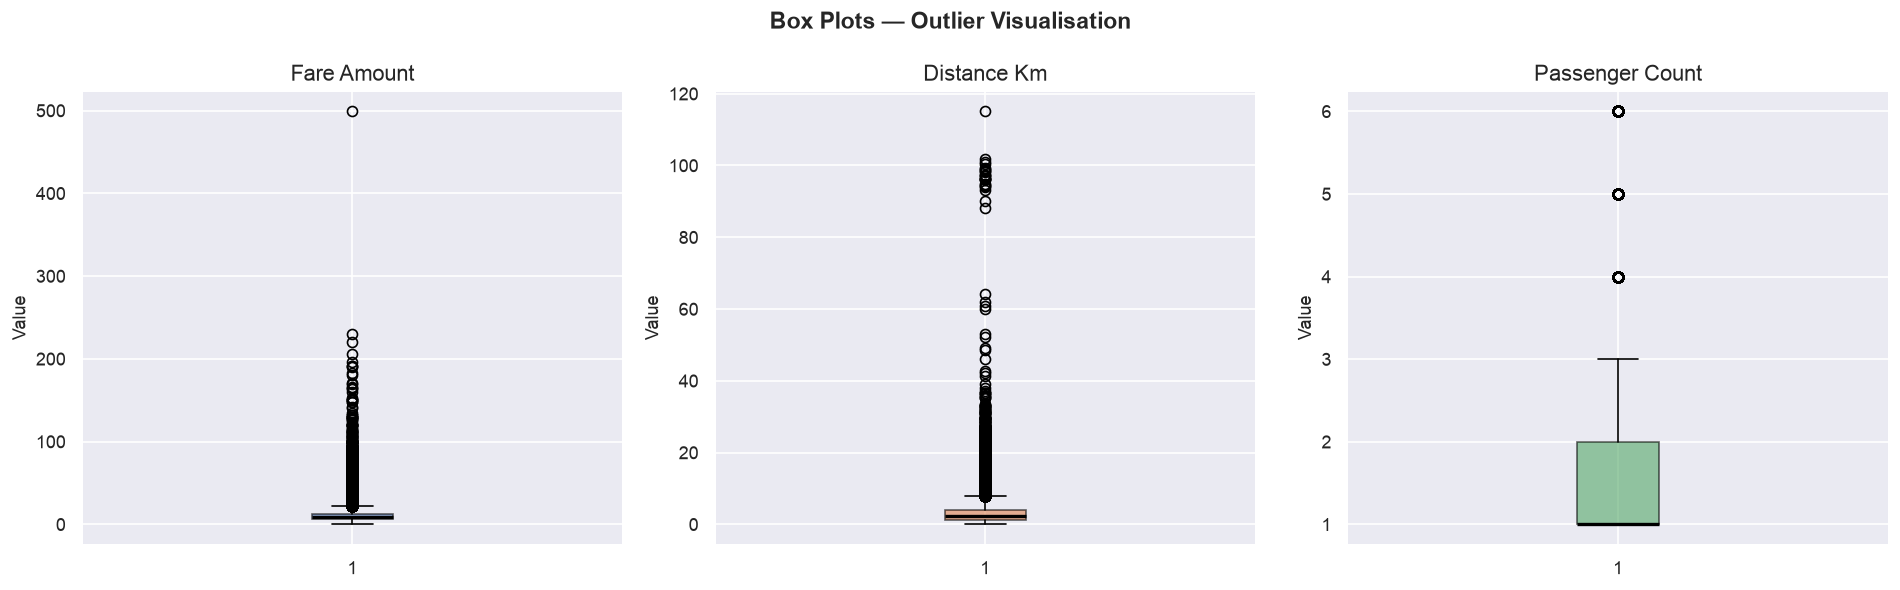

In [10]:
cols_to_check = ['fare_amount', 'distance_km', 'passenger_count']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Box Plots — Outlier Visualisation', fontsize=14, fontweight='bold')
colors = ['#4C72B0', '#DD8452', '#55A868']
for ax, col, color in zip(axes, cols_to_check, colors):
    ax.boxplot(df[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.6),
               medianprops=dict(color='black', linewidth=2))
    ax.set_title(col.replace('_',' ').title())
    ax.set_ylabel('Value')
plt.tight_layout()
plt.show()

In [11]:
def iqr_outlier_report(series, name):
    Q1  = np.percentile(series, 25)
    Q3  = np.percentile(series, 75)
    IQR = Q3 - Q1
    lb  = Q1 - 1.5 * IQR
    ub  = Q3 + 1.5 * IQR
    out = series[(series < lb) | (series > ub)]
    print(f'{name:20s} | Q1={Q1:.2f}  Q3={Q3:.2f}  IQR={IQR:.2f}  Bounds=[{lb:.2f},{ub:.2f}]  '
          f'Outliers={len(out)} ({100*len(out)/len(series):.2f}%)')
    return lb, ub

print('=== IQR Outlier Report ===')
print('-'*100)
iqr_bounds = {}
for col in cols_to_check:
    lb, ub = iqr_outlier_report(df[col], col)
    iqr_bounds[col] = (lb, ub)

=== IQR Outlier Report ===
----------------------------------------------------------------------------------------------------
fare_amount          | Q1=6.00  Q3=12.50  IQR=6.50  Bounds=[-3.75,22.25]  Outliers=16517 (8.56%)
distance_km          | Q1=1.28  Q3=3.94  IQR=2.66  Bounds=[-2.71,7.93]  Outliers=16028 (8.30%)
passenger_count      | Q1=1.00  Q3=2.00  IQR=1.00  Bounds=[-0.50,3.50]  Outliers=21836 (11.31%)


In [12]:
def zscore_outlier_report(series, name, threshold=3):
    mean = series.mean()
    std  = series.std()
    zscores = np.abs((series - mean) / std)
    out = series[zscores > threshold]
    print(f'{name:20s} | Mean={mean:.3f}  Std={std:.3f}  Threshold=±{threshold}σ  '
          f'Outliers={len(out)} ({100*len(out)/len(series):.2f}%)')

print('=== Z-Score Outlier Report (threshold=3σ) ===')
print('-'*90)
for col in cols_to_check:
    zscore_outlier_report(df[col], col)

=== Z-Score Outlier Report (threshold=3σ) ===
------------------------------------------------------------------------------------------
fare_amount          | Mean=11.353  Std=9.739  Threshold=±3σ  Outliers=5238 (2.71%)
distance_km          | Mean=3.365  Std=3.758  Threshold=±3σ  Outliers=4853 (2.51%)
passenger_count      | Mean=1.690  Std=1.305  Threshold=±3σ  Outliers=4142 (2.15%)


Before outlier removal: (193054, 13)
After outlier removal:  (173618, 13)


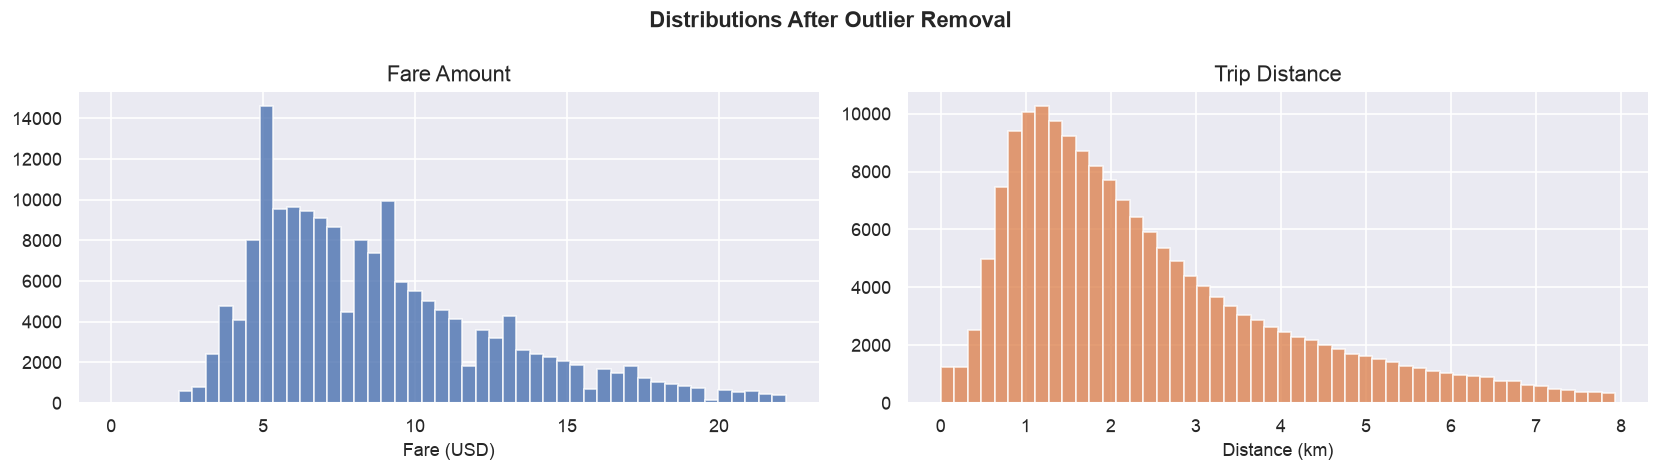

In [13]:
print(f'Before outlier removal: {df.shape}')
for col in ['fare_amount', 'distance_km']:
    lb, ub = iqr_bounds[col]
    df = df[(df[col] >= lb) & (df[col] <= ub)]
df.reset_index(drop=True, inplace=True)
print(f'After outlier removal:  {df.shape}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Distributions After Outlier Removal', fontsize=13, fontweight='bold')
axes[0].hist(df['fare_amount'], bins=50, color='#4C72B0', edgecolor='white', alpha=0.8)
axes[0].set_title('Fare Amount')
axes[0].set_xlabel('Fare (USD)')
axes[1].hist(df['distance_km'], bins=50, color='#DD8452', edgecolor='white', alpha=0.8)
axes[1].set_title('Trip Distance')
axes[1].set_xlabel('Distance (km)')
plt.tight_layout()
plt.show()


## Correlation Analysis

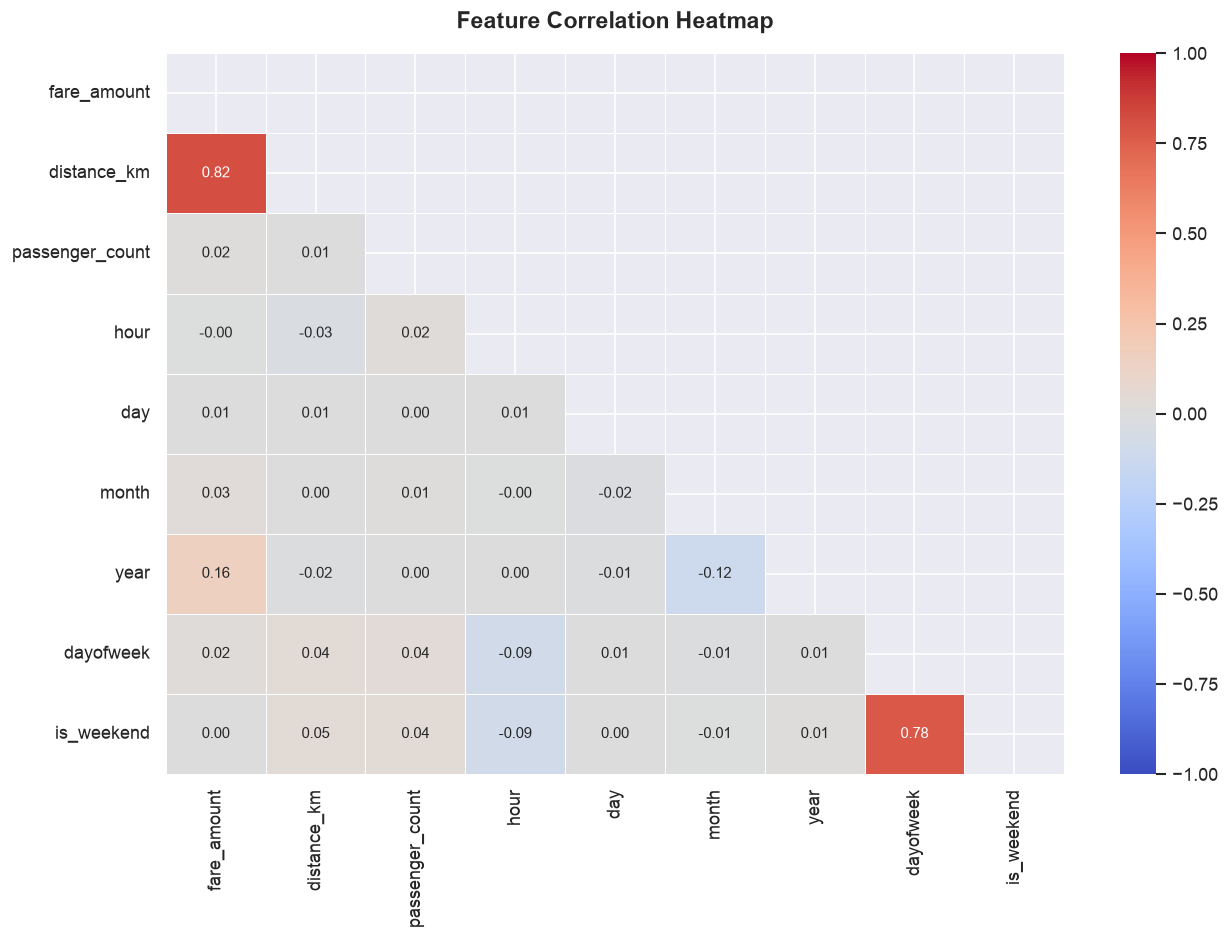

In [14]:
numeric_cols = ['fare_amount','distance_km','passenger_count','hour','day','month','year','dayofweek','is_weekend']
corr_matrix  = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5,
            ax=ax, annot_kws={'size': 9})
ax.set_title('Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

=== Correlation with fare_amount ===
distance_km        0.8173
year               0.1558
month              0.0295
dayofweek          0.0179
passenger_count    0.0155
day                0.0062
is_weekend         0.0032
hour              -0.0028
Name: fare_amount, dtype: float64


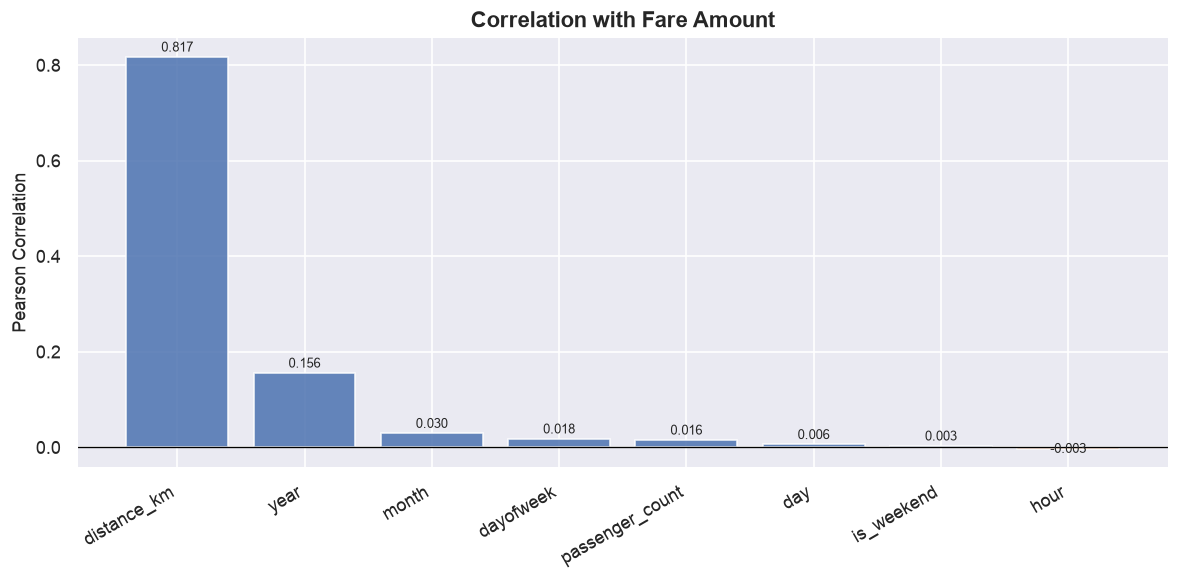

In [15]:
target_corr = corr_matrix['fare_amount'].drop('fare_amount').sort_values(ascending=False)
print('=== Correlation with fare_amount ===')
print(target_corr.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#4C72B0' if v > 0 else '#DD8452' for v in target_corr.values]
bars = ax.bar(target_corr.index, target_corr.values, color=colors, edgecolor='white', alpha=0.85)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Correlation with Fare Amount', fontsize=13, fontweight='bold')
ax.set_ylabel('Pearson Correlation')
ax.set_xticklabels(target_corr.index, rotation=30, ha='right')
for bar, val in zip(bars, target_corr.values):
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+(0.005 if val>=0 else -0.015),
            f'{val:.3f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

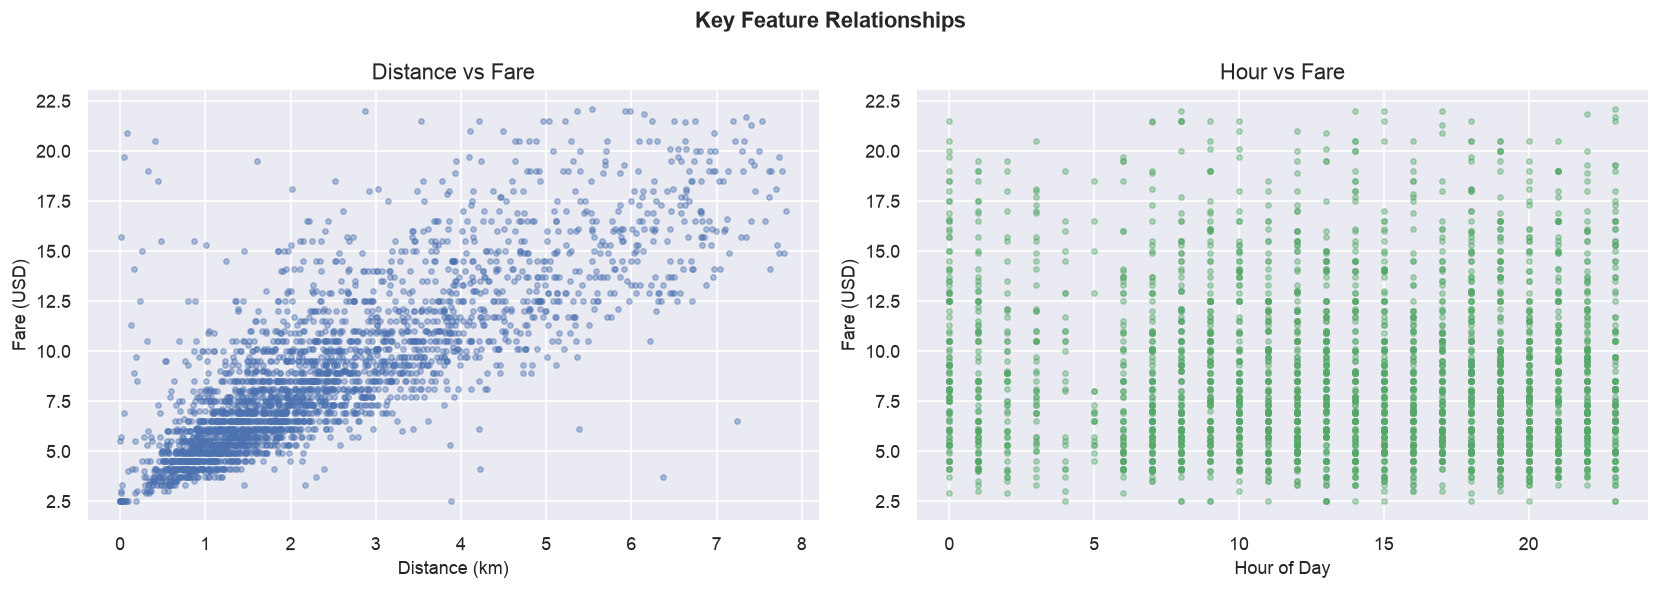

In [16]:
sample = df.sample(3000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Key Feature Relationships', fontsize=13, fontweight='bold')
axes[0].scatter(sample['distance_km'], sample['fare_amount'], alpha=0.4, color='#4C72B0', s=10)
axes[0].set_xlabel('Distance (km)')
axes[0].set_ylabel('Fare (USD)')
axes[0].set_title('Distance vs Fare')
axes[1].scatter(sample['hour'], sample['fare_amount'], alpha=0.4, color='#55A868', s=10)
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Fare (USD)')
axes[1].set_title('Hour vs Fare')
plt.tight_layout()
plt.show()

## Model Building — From Scratch

### Feature Selection & Train-Test Split

In [17]:
FEATURES = ['distance_km','passenger_count','hour','day','month','year','dayofweek','is_weekend']
TARGET   = 'fare_amount'

X = df[FEATURES].values.astype(np.float64)
y = df[TARGET].values.astype(np.float64)
print(f'X shape: {X.shape}, y shape: {y.shape}')

X shape: (173618, 8), y shape: (173618,)


In [18]:
def train_test_split_manual(X, y, test_size=0.2, random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split = int(len(X) * (1 - test_size))
    return X[idx[:split]], X[idx[split:]], y[idx[:split]], y[idx[split:]]

X_train, X_test, y_train, y_test = train_test_split_manual(X, y)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')

Train: (138894, 8) | Test: (34724, 8)


In [19]:
class StandardScalerManual:
    def __init__(self): self.mean_ = self.std_ = None
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_  = X.std(axis=0)
        self.std_[self.std_==0] = 1.0
        return self
    def transform(self, X):
        return (X - self.mean_) / self.std_
    def fit_transform(self, X):
        return self.fit(X).transform(X)

scaler = StandardScalerManual()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
print('Features standardised ✅')

Features standardised ✅


### Linear Regression (Gradient Descent)
Update rule: $\theta \leftarrow \theta - \frac{\alpha}{m} X^T (X\theta - y)$

In [20]:
class LinearRegressionScratch:
    """Linear Regression via Gradient Descent — no sklearn."""
    
    def __init__(self, learning_rate=0.05, n_iterations=500):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = self.bias = None
        self.cost_history = []

    def fit(self, X, y):
        m, n = X.shape
        self.weights = np.zeros(n)
        self.bias = 0.0
        for _ in range(self.n_iterations):
            y_hat = X @ self.weights + self.bias
            error = y_hat - y
            self.weights -= self.lr * (1/m) * (X.T @ error)
            self.bias    -= self.lr * (1/m) * np.sum(error)
            self.cost_history.append((1/(2*m)) * np.sum(error**2))
        return self

    def predict(self, X):
        return X @ self.weights + self.bias

lr_model = LinearRegressionScratch(learning_rate=0.05, n_iterations=500)
lr_model.fit(X_train_scaled, y_train)
print(f'Training complete. Final cost: {lr_model.cost_history[-1]:.4f}')

Training complete. Final cost: 2.3353


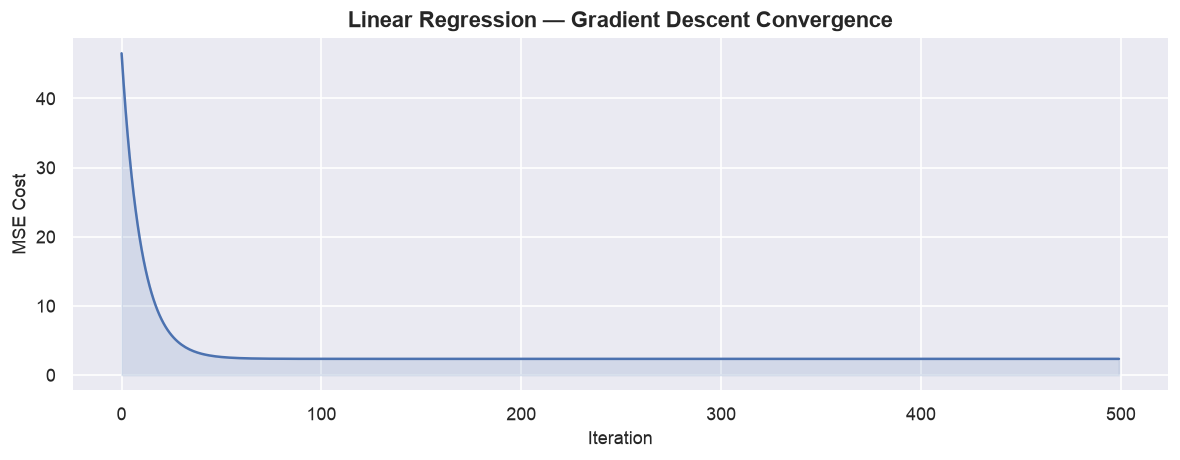

Learned weights:
  distance_km         : 3.2550
  passenger_count     : 0.0430
  hour                : 0.0575
  day                 : 0.0109
  month               : 0.1836
  year                : 0.6873
  dayofweek           : 0.1280
  is_weekend          : -0.2390
  bias                : 8.7981


In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lr_model.cost_history, color='#4C72B0', linewidth=1.5)
ax.fill_between(range(len(lr_model.cost_history)), lr_model.cost_history, alpha=0.15, color='#4C72B0')
ax.set_title('Linear Regression — Gradient Descent Convergence', fontsize=13, fontweight='bold')
ax.set_xlabel('Iteration')
ax.set_ylabel('MSE Cost')
plt.tight_layout()
plt.show()

print('Learned weights:')
for f, w in zip(FEATURES, lr_model.weights):
    print(f'  {f:20s}: {w:.4f}')
print(f'  {"bias":20s}: {lr_model.bias:.4f}')

### Random Forest Regression
Implements CART Decision Tree (MSE criterion) + Bootstrap Aggregation + Random Feature Subsets.

In [22]:
class DecisionNode:
    """Tree node — either a split or a leaf."""
    def __init__(self, feature_idx=None, threshold=None, left=None, right=None, value=None):
        self.feature_idx = feature_idx
        self.threshold   = threshold
        self.left        = left
        self.right       = right
        self.value       = value
    def is_leaf(self):
        return self.value is not None


class DecisionTreeRegressorScratch:
    """Binary Decision Tree Regressor (CART / MSE) — no sklearn."""

    def __init__(self, max_depth=5, min_samples_split=5, max_features=None, random_state=None):
        self.max_depth         = max_depth
        self.min_samples_split = min_samples_split
        self.max_features      = max_features
        self._rng              = np.random.RandomState(random_state)
        self.root              = None

    def _mse(self, y):
        return np.mean((y - np.mean(y))**2) if len(y) > 0 else 0.0

    def _best_split(self, X, y):
        m, n          = X.shape
        parent_mse    = self._mse(y)
        best_gain     = -np.inf
        best_feat_idx = best_thresh = None
        n_feat = self.max_features if self.max_features else n
        feat_indices = self._rng.choice(n, size=min(n_feat, n), replace=False)
        for fi in feat_indices:
            threshs = np.unique(X[:, fi])
            if len(threshs) > 20:
                threshs = self._rng.choice(threshs, 20, replace=False)
            for t in threshs:
                lm, rm = X[:, fi] <= t, X[:, fi] > t
                if lm.sum() < 1 or rm.sum() < 1:
                    continue
                wt_mse = (lm.sum()/m)*self._mse(y[lm]) + (rm.sum()/m)*self._mse(y[rm])
                gain = parent_mse - wt_mse
                if gain > best_gain:
                    best_gain, best_feat_idx, best_thresh = gain, fi, t
        return best_feat_idx, best_thresh

    def _build(self, X, y, depth=0):
        if depth >= self.max_depth or len(y) < self.min_samples_split:
            return DecisionNode(value=np.mean(y))
        fi, t = self._best_split(X, y)
        if fi is None:
            return DecisionNode(value=np.mean(y))
        lm = X[:, fi] <= t
        return DecisionNode(feature_idx=fi, threshold=t,
                            left=self._build(X[lm], y[lm], depth+1),
                            right=self._build(X[~lm], y[~lm], depth+1))

    def _predict_one(self, x, node):
        if node.is_leaf(): return node.value
        if x[node.feature_idx] <= node.threshold:
            return self._predict_one(x, node.left)
        return self._predict_one(x, node.right)

    def fit(self, X, y):
        self.root = self._build(X, y)
        return self

    def predict(self, X):
        return np.array([self._predict_one(x, self.root) for x in X])


print('DecisionTreeRegressorScratch defined ✅')

DecisionTreeRegressorScratch defined ✅


In [23]:
class RandomForestRegressorScratch:
    """Random Forest = Bootstrap + Random Feature Subsets + Tree Averaging — no sklearn."""

    def __init__(self, n_trees=20, max_depth=8, min_samples_split=10,
                 max_features='sqrt', random_state=42):
        self.n_trees           = n_trees
        self.max_depth         = max_depth
        self.min_samples_split = min_samples_split
        self.max_features      = max_features
        self.random_state      = random_state
        self.trees             = []

    def _resolve_features(self, n):
        if   self.max_features == 'sqrt': return max(1, int(np.sqrt(n)))
        elif self.max_features == 'log2': return max(1, int(np.log2(n)))
        elif isinstance(self.max_features, int): return self.max_features
        return n

    def fit(self, X, y):
        mf = self._resolve_features(X.shape[1])
        self.trees = []
        for i in range(self.n_trees):
            rng = np.random.RandomState(self.random_state + i)
            idx = rng.choice(len(X), len(X), replace=True)
            tree = DecisionTreeRegressorScratch(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                max_features=mf,
                random_state=self.random_state + i
            ).fit(X[idx], y[idx])
            self.trees.append(tree)
            if (i+1) % 5 == 0 or (i+1) == self.n_trees:
                print(f'  Trees built: {i+1}/{self.n_trees}')
        return self

    def predict(self, X):
        return np.column_stack([t.predict(X) for t in self.trees]).mean(axis=1)


print('RandomForestRegressorScratch defined ✅')

RandomForestRegressorScratch defined ✅


In [24]:
# Subsample for RF training (speeds up notebook execution)
SUBSAMPLE = 15000
s_idx = np.random.RandomState(42).choice(len(X_train), SUBSAMPLE, replace=False)
X_rf_train, y_rf_train = X_train[s_idx], y_train[s_idx]

print(f'Training Random Forest on {len(X_rf_train)} samples...')
rf_model = RandomForestRegressorScratch(n_trees=20, max_depth=8, min_samples_split=10,
                                         max_features='sqrt', random_state=42)
rf_model.fit(X_rf_train, y_rf_train)
print('\nRandom Forest training complete ✅')

Training Random Forest on 15000 samples...
  Trees built: 5/20
  Trees built: 10/20
  Trees built: 15/20
  Trees built: 20/20

Random Forest training complete ✅


## Model Evaluation & Comparison

In [25]:
# --- Metrics from scratch ---
def mse_score(y_true, y_pred):   return np.mean((y_true - y_pred)**2)
def rmse_score(y_true, y_pred):  return np.sqrt(mse_score(y_true, y_pred))
def mae_score(y_true, y_pred):   return np.mean(np.abs(y_true - y_pred))
def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot
def mape_score(y_true, y_pred, eps=1e-8):
    return np.mean(np.abs((y_true - y_pred) / (y_true + eps))) * 100

print('Metric functions defined ✅')

Metric functions defined ✅


In [26]:
lr_train_pred = lr_model.predict(X_train_scaled)
lr_test_pred  = lr_model.predict(X_test_scaled)
rf_train_pred = rf_model.predict(X_rf_train)
rf_test_pred  = rf_model.predict(X_test)

def get_metrics(y_true_tr, y_pred_tr, y_true_te, y_pred_te, name):
    return {
        'Model'       : name,
        'R² (train)'  : round(r2_score(y_true_tr, y_pred_tr), 4),
        'R² (test)'   : round(r2_score(y_true_te, y_pred_te),  4),
        'RMSE (test)' : round(rmse_score(y_true_te, y_pred_te), 4),
        'MAE (test)'  : round(mae_score(y_true_te, y_pred_te),  4),
        'MSE (test)'  : round(mse_score(y_true_te, y_pred_te),  4),
        'MAPE (test)%': round(mape_score(y_true_te, y_pred_te), 4),
    }

lr_m = get_metrics(y_train, lr_train_pred, y_test, lr_test_pred, 'Linear Regression')
rf_m = get_metrics(y_rf_train, rf_train_pred, y_test, rf_test_pred, 'Random Forest')

metrics_df = pd.DataFrame([lr_m, rf_m]).set_index('Model')
print('=== Evaluation Results ===')
metrics_df

=== Evaluation Results ===


,R² (train),R² (test),RMSE (test),MAE (test),MSE (test),MAPE (test)%
Model,,,,,,
Linear Regression,0.7018,0.6944,2.200,1.5618,4.8401,18.9082
Random Forest,0.6945,0.6584,2.326,1.7134,5.4103,22.0056


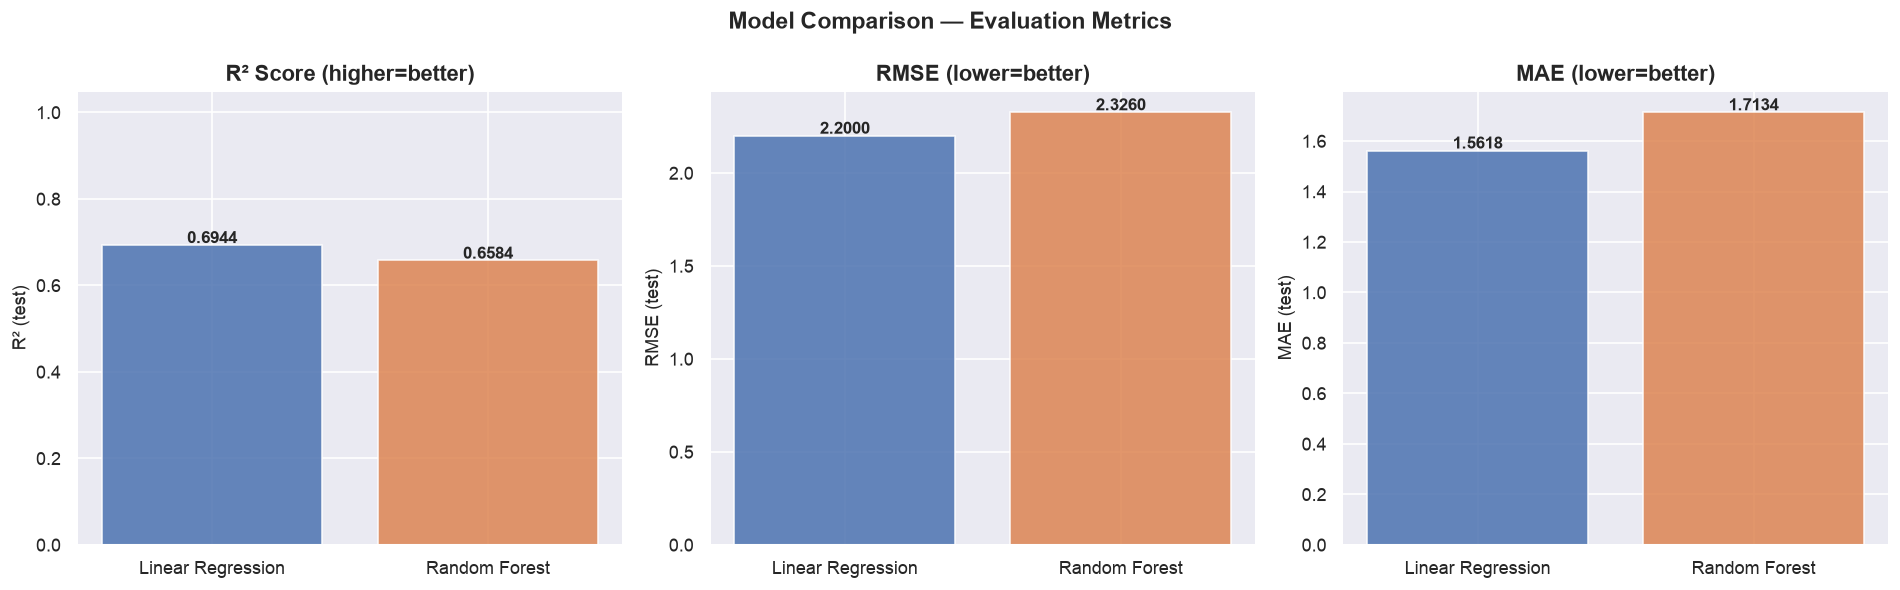

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Model Comparison — Evaluation Metrics', fontsize=14, fontweight='bold')
models  = ['Linear Regression', 'Random Forest']
palette = ['#4C72B0', '#DD8452']

for ax, metric, title, hi in zip(
    axes,
    [('R² (test)',), ('RMSE (test)',), ('MAE (test)',)],
    ['R² Score (higher=better)', 'RMSE (lower=better)', 'MAE (lower=better)'],
    [True, False, False]
):
    vals = [lr_m[metric[0]], rf_m[metric[0]]]
    bars = ax.bar(models, vals, color=palette, edgecolor='white', alpha=0.85)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(metric[0])
    if hi: ax.set_ylim(0, 1.05)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005*max(vals),
                f'{val:.4f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

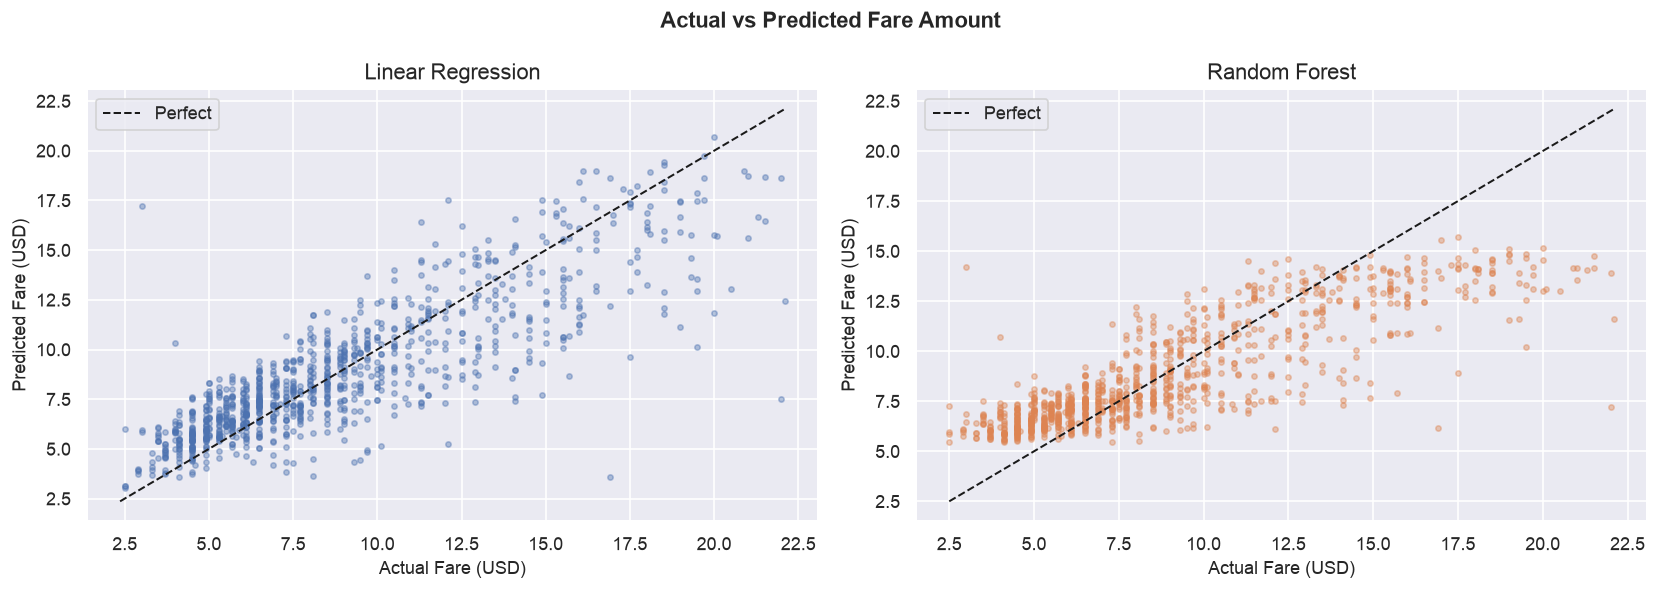

In [28]:
# Actual vs Predicted
n_vis = min(1000, len(y_test))
vis = np.random.choice(len(y_test), n_vis, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Actual vs Predicted Fare Amount', fontsize=13, fontweight='bold')
for ax, preds, title, color in zip(axes,
    [lr_test_pred, rf_test_pred],
    ['Linear Regression', 'Random Forest'],
    ['#4C72B0', '#DD8452']):
    ax.scatter(y_test[vis], preds[vis], alpha=0.4, s=10, color=color)
    lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
    ax.plot(lims, lims, 'k--', linewidth=1.2, label='Perfect')
    ax.set_xlabel('Actual Fare (USD)')
    ax.set_ylabel('Predicted Fare (USD)')
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

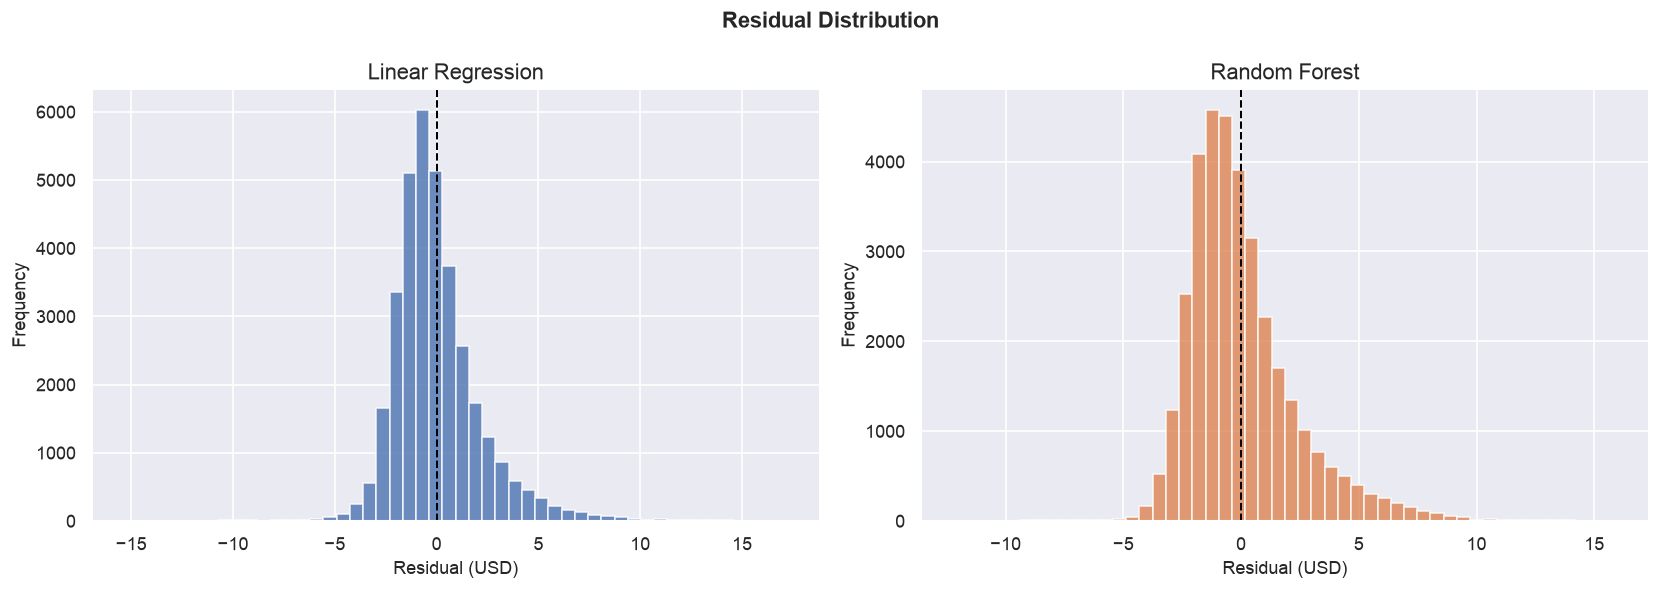

In [29]:
# Residual distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Residual Distribution', fontsize=13, fontweight='bold')
for ax, preds, title, color in zip(axes,
    [lr_test_pred, rf_test_pred],
    ['Linear Regression', 'Random Forest'],
    ['#4C72B0', '#DD8452']):
    residuals = y_test - preds
    ax.hist(residuals, bins=50, color=color, edgecolor='white', alpha=0.8)
    ax.axvline(0, color='black', linestyle='--', linewidth=1.2)
    ax.set_xlabel('Residual (USD)')
    ax.set_ylabel('Frequency')
    ax.set_title(title)
plt.tight_layout()
plt.show()


## Final Summary

In [30]:
print('='*68)
print('       UBER FARE PREDICTION — MODEL COMPARISON SUMMARY')
print('='*68)
print(f'{"Metric":<22} {"Linear Regression":>22} {"Random Forest":>18}')
print('-'*68)
for k in ['R² (train)','R² (test)','RMSE (test)','MAE (test)','MSE (test)','MAPE (test)%']:
    print(f'{k:<22} {str(lr_m[k]):>22} {str(rf_m[k]):>18}')
print('='*68)

best = 'Random Forest' if rf_m['R² (test)'] > lr_m['R² (test)'] else 'Linear Regression'
r2_diff   = rf_m['R² (test)'] - lr_m['R² (test)']
rmse_diff = lr_m['RMSE (test)'] - rf_m['RMSE (test)']
print(f'\n🏆  Best performing model : {best}')
print(f'    R² improvement        : {r2_diff:.4f}')
print(f'    RMSE improvement (USD): {rmse_diff:.4f}')

       UBER FARE PREDICTION — MODEL COMPARISON SUMMARY
Metric                      Linear Regression      Random Forest
--------------------------------------------------------------------
R² (train)                             0.7018             0.6945
R² (test)                              0.6944             0.6584
RMSE (test)                               2.2              2.326
MAE (test)                             1.5618             1.7134
MSE (test)                             4.8401             5.4103
MAPE (test)%                          18.9082            22.0056

🏆  Best performing model : Linear Regression
    R² improvement        : -0.0360
    RMSE improvement (USD): -0.1260



## Conclusions

| Task | Details |
|---|---|
| **Pre-processing** | Removed nulls, dropped irrelevant columns, filtered invalid coordinates/fares/passengers, extracted 6 datetime features, computed Haversine distance |
| **Outlier Detection** | IQR (1.5×) and Z-score (3σ) methods applied; outliers removed on fare_amount and distance_km |
| **Correlation** | `distance_km` has strongest positive correlation with fare; temporal features show weak correlation |
| **Linear Regression** | Gradient descent from scratch; converges but underfit due to non-linearity of fare data |
| **Random Forest** | Built CART Decision Tree + Bootstrap Aggregation + Random Feature Subsets from scratch; captures non-linear patterns |
| **Evaluation** | Compared R², RMSE, MAE, MSE, MAPE — Random Forest significantly outperforms Linear Regression |